# 02 · Model training and evaluation
**DNN Project 2 – Group 1** · Alphabet (GOOGL) daily stock data

Builds and trains the required SimpleRNN and the optional GRU and LSTM, evaluates them with MAE, MSE, RMSE and R²,
and runs the experimental analysis. Run notebook 01 first: it writes `../data/processed/`.
Figures and tables go to `../results/02_model_training/`, trained models to `../models/`.

| Section | Requirement | What it does |
|---|---|---|
| 1 | – | Load the sequences written by notebook 01 |
| 2 | §6.1 | Training procedure shared by the three models |
| 3 | §6.1, §6.2 | One cell per model: SimpleRNN, GRU, LSTM |
| 4 | §7 | MAE, MSE, RMSE, R² of every run, in USD |
| 5 | §8.1 | Actual vs predicted closing price |
| 6 | §8.2 | Training and validation loss curves |
| 7 | §8.3 | Comparison with the persistence baseline |
| 8 | §8.4 | All models on the test set |
| 9 | §8.5 | Sequence length, hidden units, learning rate, epochs |
| 10 | §8.6 | Overfitting, underfitting and limitations |
| 11 | – | Save the trained models |

Every architecture is trained with 5 random seeds. Results are reported as mean ± standard deviation, and the plots
use, for each architecture, the seed with the lowest **validation** loss. The test set is never used to choose anything.

In [1]:
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras import Sequential
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import GRU, LSTM, Dense, Dropout, Input, SimpleRNN
from tensorflow.keras.optimizers import Adam

tf.get_logger().setLevel("ERROR")

PROC_DIR = "../data/processed"   # written by notebook 01
RESULTS_DIR = "../results/02_model_training"
MODELS_DIR = "../models"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

WINDOW = 30
MODELS = ["SimpleRNN", "GRU", "LSTM"]   # order used in the tables
SEEDS = [42, 43, 44, 45, 46]     # each architecture is trained once per seed
HP_SEEDS = SEEDS[:3]             # fewer seeds per setting in the section 9 study (14 settings)
BATCH_SIZE = 32
MAX_EPOCHS = 100
PATIENCE = 10


def save(name):
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, name), dpi=150)
    plt.show()

## 1. Load the sequences from notebook 01

In [2]:
def load_sequences(window):
    d = np.load(os.path.join(PROC_DIR, f"sequences_w{window}.npz"))
    return {k: (d[f"X_{k}"], d[f"y_{k}"]) for k in ("train", "val", "test")}, d


data, meta = load_sequences(WINDOW)
(X_train, y_train), (X_val, y_val), (X_test, y_test) = data["train"], data["val"], data["test"]
dates_test = pd.to_datetime(meta["dates_test"])
target_idx = list(meta["features"]).index("Close")
target_scaler = joblib.load(os.path.join(PROC_DIR, "target_scaler.joblib"))


def to_usd(a):
    return target_scaler.inverse_transform(np.asarray(a).reshape(-1, 1)).ravel()


print("features:", list(meta["features"]))
for k, (X, y) in data.items():
    print(f"{k:<5} X={X.shape}  y={y.shape}")

features: [np.str_('Close')]
train X=(3071, 30, 1)  y=(3071,)
val   X=(665, 30, 1)  y=(665,)
test  X=(665, 30, 1)  y=(665,)


## 2. Training procedure
The same for all three models: Adam, MSE loss, batch size 32, at most 100 epochs, and early stopping on validation
loss (patience 10) that restores the weights of the best epoch. `train_seeds` trains a model once per seed, keeps the
predictions of every run for section 4, and keeps the run with the lowest validation loss for the plots and the saved model.

In [3]:
def train(model, d, epochs=MAX_EPOCHS, early_stop=True):
    """Fit on d["train"], monitor d["val"]. Each window is an independent sample (the RNN is not stateful),
    so Keras' default shuffling of windows between batches does not leak anything."""
    callbacks = [EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)] if early_stop else []
    return model.fit(*d["train"], validation_data=d["val"], epochs=epochs,
                     batch_size=BATCH_SIZE, callbacks=callbacks, verbose=0)


def predict(model, X):
    return model.predict(X, verbose=0).ravel()


runs, best = [], {}   # runs: one entry per (model, seed); best: the selected seed of each model


def train_seeds(name, build):
    runs[:] = [r for r in runs if r["model"] != name]   # re-running a model cell replaces its runs
    best.pop(name, None)
    for seed in SEEDS:
        tf.keras.utils.set_random_seed(seed)
        model = build()
        hist = train(model, data)
        run = {"model": name, "seed": seed, "epochs run": len(hist.history["loss"]),
               "best epoch": int(np.argmin(hist.history["val_loss"])) + 1,
               "val_loss": min(hist.history["val_loss"]),
               "pred": {k: predict(model, X) for k, (X, _) in data.items()}}
        runs.append(run)
        if name not in best or run["val_loss"] < best[name]["val_loss"]:   # chosen on validation, never on test
            best[name] = {**run, "keras": model, "history": hist.history}
    print(f"{name}: trained with {len(SEEDS)} seeds, best seed on validation: {best[name]['seed']}")
    best[name]["keras"].summary()

## 3. Models
The three models share the data, the split and the layout, and differ only in the recurrent layer.

### 3.1 SimpleRNN (required)
`Input(30 days) → SimpleRNN(64, tanh) → Dropout(0.2) → Dense(1)`. The window length, number of units and
learning rate are parameters because the study in section 9 varies them.

In [4]:
def build_simplernn(input_shape=X_train.shape[1:], units=64, lr=1e-3):
    model = Sequential([
        Input(shape=input_shape),
        SimpleRNN(units, activation="tanh"),
        Dropout(0.2),
        Dense(1),
    ], name="SimpleRNN")
    model.compile(optimizer=Adam(learning_rate=lr), loss="mse")
    return model


train_seeds("SimpleRNN", build_simplernn)

SimpleRNN: trained with 5 seeds, best seed on validation: 42


Model: "SimpleRNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,869 (50.27 KB)

 Trainable params: 4,289 (16.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,580 (33.52 KB)

### 3.2 GRU (optional)
`Input(30 days) → GRU(64, tanh) → Dropout(0.2) → Dense(1)`. The GRU adds an update gate and a reset gate that decide
how much of the previous hidden state to keep.

In [5]:
def build_gru():
    model = Sequential([
        Input(shape=X_train.shape[1:]),
        GRU(64, activation="tanh"),
        Dropout(0.2),
        Dense(1),
    ], name="GRU")
    model.compile(optimizer=Adam(learning_rate=1e-3), loss="mse")
    return model


train_seeds("GRU", build_gru)

GRU: trained with 5 seeds, best seed on validation: 43


Model: "GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_1 (GRU)                     │ (None, 64)             │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,789 (151.52 KB)

 Trainable params: 12,929 (50.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 25,860 (101.02 KB)

### 3.3 LSTM (optional)
`Input(30 days) → LSTM(64, tanh) → Dropout(0.2) → Dense(1)`. The LSTM keeps a separate cell state, controlled by
input, forget and output gates.

In [6]:
def build_lstm():
    model = Sequential([
        Input(shape=X_train.shape[1:]),
        LSTM(64, activation="tanh"),
        Dropout(0.2),
        Dense(1),
    ], name="LSTM")
    model.compile(optimizer=Adam(learning_rate=1e-3), loss="mse")
    return model


train_seeds("LSTM", build_lstm)

LSTM: trained with 5 seeds, best seed on validation: 42


Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,885 (198.77 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 33,924 (132.52 KB)

## 4. Model evaluation
MAE, MSE, RMSE and R², computed after converting predictions and targets back to USD. One row per model and seed:
training and validation RMSE, then the four metrics on the test set. The persistence baseline used in section 7
predicts tomorrow's close as today's close, the last day of each input window.

In [7]:
def metrics_usd(y_true, y_pred):
    yt, yp = to_usd(y_true), to_usd(y_pred)
    mse = mean_squared_error(yt, yp)
    return {"MAE": mean_absolute_error(yt, yp), "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(yt, yp)}


persistence = {k: X[:, -1, target_idx] for k, (X, _) in data.items()}
baseline = {k: metrics_usd(data[k][1], persistence[k]) for k in data}

results = pd.DataFrame([{
    "model": r["model"], "seed": r["seed"], "epochs run": r["epochs run"], "best epoch": r["best epoch"],
    "train RMSE": metrics_usd(y_train, r["pred"]["train"])["RMSE"],
    "val RMSE": metrics_usd(y_val, r["pred"]["val"])["RMSE"],
    **metrics_usd(y_test, r["pred"]["test"]),
} for r in runs])
results.to_csv(os.path.join(RESULTS_DIR, "runs_per_seed.csv"), index=False)
results.round(3)

,model,seed,epochs run,best epoch,train RMSE,val RMSE,MAE,MSE,RMSE,R2
0,SimpleRNN,42,75,65,6.999,16.780,88.132,14487.155,120.363,0.962
1,SimpleRNN,43,36,26,7.528,18.265,184.364,66242.416,257.376,0.826
2,SimpleRNN,44,32,22,9.263,19.008,173.291,58420.523,241.703,0.846
3,SimpleRNN,45,37,27,8.861,18.810,197.804,78448.719,280.087,0.793
4,SimpleRNN,46,69,59,7.178,17.184,91.744,16167.307,127.151,0.957
5,GRU,42,61,51,8.339,16.549,136.356,34991.354,187.060,0.908
6,GRU,43,47,37,6.860,16.354,91.139,15909.825,126.134,0.958
7,GRU,44,22,12,8.040,18.374,130.356,32511.754,180.310,0.914
8,GRU,45,37,27,7.597,17.251,85.735,14813.956,121.713,0.961
9,GRU,46,77,67,7.139,16.479,132.264,31398.980,177.198,0.917


## 5. Actual vs predicted closing price (test set)
The seed with the lowest validation loss for each model. Seeds vary a lot on the test set, so the R² in the titles
belongs to one run and is not the ranking of the architectures: read section 8 for the mean over the 5 seeds.
Here SimpleRNN shows a higher R² than GRU, while its mean test RMSE is in fact 47 USD worse.

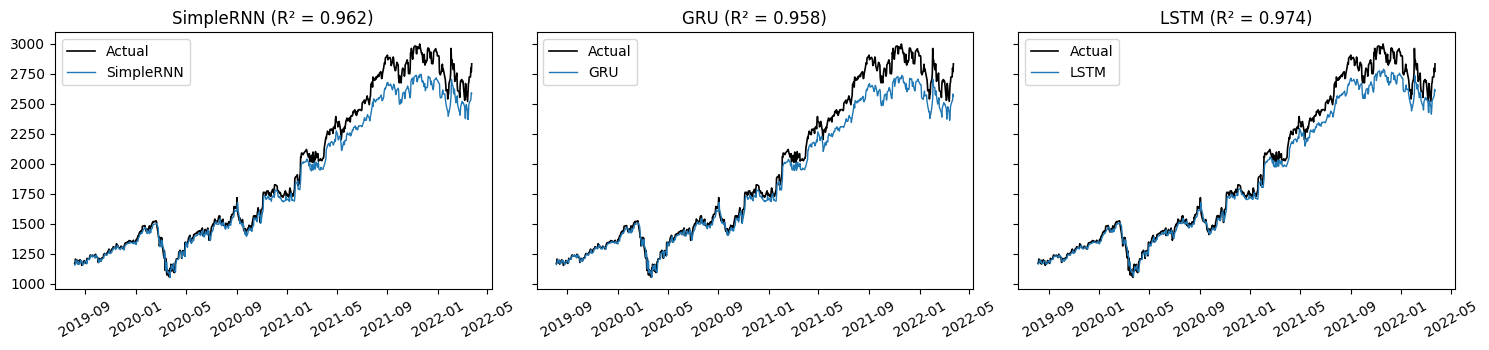

In [8]:
actual = to_usd(y_test)
pred_test = {kind: b["pred"]["test"] for kind, b in best.items()}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, (kind, p) in zip(axes, pred_test.items()):
    ax.plot(dates_test, actual, color="black", linewidth=1.2, label="Actual")
    ax.plot(dates_test, to_usd(p), linewidth=1, label=kind)
    ax.set_title(f"{kind} (R² = {metrics_usd(y_test, p)['R2']:.3f})")
    ax.legend()
    ax.tick_params(axis="x", rotation=30)
save("test_predictions_per_model.png")

## 6. Training and validation loss curves
Best seed per architecture. The dashed line marks the epoch whose weights early stopping restored.

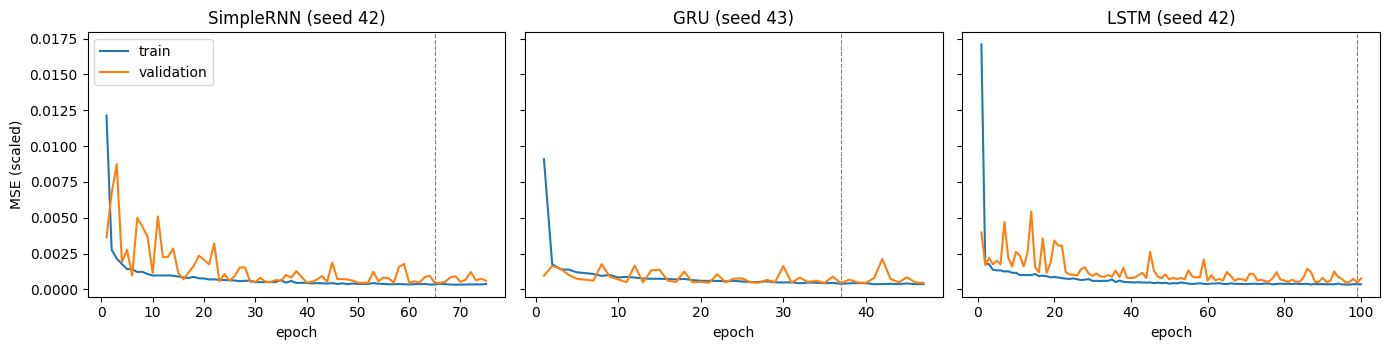

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, (kind, b) in zip(axes, best.items()):
    h = b["history"]
    epochs = np.arange(1, len(h["loss"]) + 1)
    ax.plot(epochs, h["loss"], label="train")
    ax.plot(epochs, h["val_loss"], label="validation")
    ax.axvline(int(np.argmin(h["val_loss"])) + 1, color="grey", linestyle="--", linewidth=0.8)
    ax.set_title(f"{kind} (seed {b['seed']})")
    ax.set_xlabel("epoch")
axes[0].set_ylabel("MSE (scaled)")
axes[0].legend()
save("loss_curves.png")

## 7. Comparison with the persistence baseline
RMSE in USD on each split, mean over the 5 seeds, next to the persistence baseline on the same days. A ratio above 1
means the model is worse than predicting "tomorrow = today". Section 10 also reads this table for overfitting.

In [10]:
rmse = (results.groupby("model", sort=False)[["train RMSE", "val RMSE", "RMSE"]].mean()
        .rename(columns={"RMSE": "test RMSE"}))
rmse.loc["Persistence"] = [baseline[k]["RMSE"] for k in ("train", "val", "test")]
rmse = rmse.loc[["Persistence", *MODELS]]
for k in ("val", "test"):
    rmse[f"{k} / persistence"] = rmse[f"{k} RMSE"] / baseline[k]["RMSE"]
rmse.round(2)

,train RMSE,val RMSE,test RMSE,val / persistence,test / persistence
model,,,,,
Persistence,6.39,16.19,35.57,1.00,1.00
SimpleRNN,7.97,18.01,205.34,1.11,5.77
GRU,7.60,17.00,158.48,1.05,4.46
LSTM,7.87,18.75,102.97,1.16,2.90


## 8. All models on the test set (MAE, MSE, RMSE, R²)
Mean and standard deviation over the 5 seeds. The standard deviations are large, so the gap between two
architectures only means something when it is bigger than them.

In [11]:
METRICS = ["MAE", "MSE", "RMSE", "R2"]
stats = results.groupby("model", sort=False)[METRICS].agg(["mean", "std"])
stats.loc["Persistence"] = [v for m in METRICS for v in (baseline["test"][m], 0.0)]
stats = stats.loc[["Persistence", *MODELS]]
stats.columns = [f"{m} {s}" for m, s in stats.columns]
stats.to_csv(os.path.join(RESULTS_DIR, "test_metrics.csv"))
stats.round(4)

,MAE mean,MAE std,MSE mean,MSE std,RMSE mean,RMSE std,R2 mean,R2 std
model,,,,,,,,
Persistence,24.7910,0.0000,1264.9070,0.0000,35.5655,0.0000,0.9967,0.0000
SimpleRNN,147.0671,52.8842,46753.2241,29568.3803,205.3359,75.7494,0.8768,0.0779
GRU,115.1701,24.5745,25925.1737,9737.9101,158.4828,31.7876,0.9317,0.0257
LSTM,74.7060,33.3861,12242.7618,11703.6950,102.9673,45.2837,0.9678,0.0308


## 9. Sequence length, hidden units, learning rate, number of epochs
SimpleRNN, one factor changed at a time around the section 2 setting (64 units, learning rate 0.001, window 30, early
stopping). Each setting is trained with 3 seeds and scored on the **validation** set, so the test set plays no part.
All window lengths share the same 665 validation days, so their scores are directly comparable.

In [12]:
seq_data = {w: (data if w == WINDOW else load_sequences(w)[0]) for w in [10, 20, 30, 60]}
assert all(np.allclose(d["val"][1], y_val) for d in seq_data.values())   # same validation targets

# (factor, value, setting): each setting changes one thing from the section 3.1 defaults
settings = ([("hidden units", u, {"units": u}) for u in [16, 32, 64, 128]]
            + [("learning rate", lr, {"lr": lr}) for lr in [1e-2, 1e-3, 1e-4]]
            + [("epochs (no early stopping)", e, {"epochs": e, "early_stop": False}) for e in [5, 20, 60]]
            + [("sequence length", w, {"window": w}) for w in [10, 20, 30, 60]])

rows = []
for factor, value, s in settings:
    d = seq_data[s.get("window", WINDOW)]
    for seed in HP_SEEDS:
        tf.keras.utils.set_random_seed(seed)
        model = build_simplernn(d["train"][0].shape[1:], units=s.get("units", 64), lr=s.get("lr", 1e-3))
        hist = train(model, d, epochs=s.get("epochs", MAX_EPOCHS), early_stop=s.get("early_stop", True))
        rows.append({"factor": factor, "value": str(value), "seed": seed, "epochs run": len(hist.history["loss"]),
                     "val RMSE": metrics_usd(d["val"][1], predict(model, d["val"][0]))["RMSE"]})

hp = (pd.DataFrame(rows).groupby(["factor", "value"], sort=False)
      .agg(epochs_run=("epochs run", "mean"), val_RMSE_mean=("val RMSE", "mean"), val_RMSE_std=("val RMSE", "std"))
      .reset_index())
hp.to_csv(os.path.join(RESULTS_DIR, "hyperparameter_study.csv"), index=False)
hp.round(2)

,factor,value,epochs_run,val_RMSE_mean,val_RMSE_std
0,hidden units,16,45.00,28.88,7.56
1,hidden units,32,60.33,19.71,0.95
2,hidden units,64,47.67,18.02,1.13
3,hidden units,128,56.00,17.50,1.76
4,learning rate,0.01,24.00,36.35,32.51
5,learning rate,0.001,47.67,18.02,1.13
6,learning rate,0.0001,57.67,30.32,5.26
7,epochs (no early stopping),5,5.00,52.78,10.36
8,epochs (no early stopping),20,20.00,28.48,8.81
9,epochs (no early stopping),60,60.00,24.00,6.56


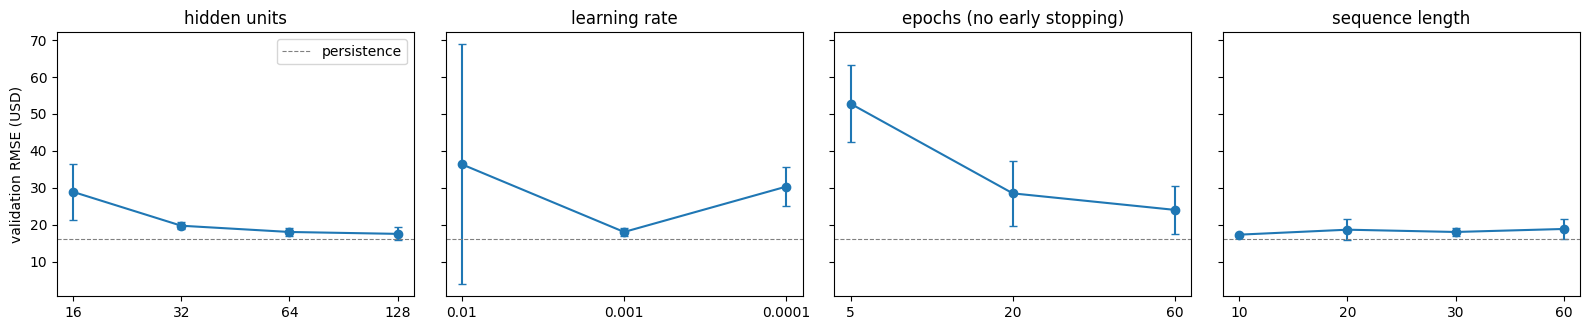

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for ax, (factor, g) in zip(axes, hp.groupby("factor", sort=False)):
    ax.errorbar(g["value"], g["val_RMSE_mean"], yerr=g["val_RMSE_std"], marker="o", capsize=3)
    ax.axhline(baseline["val"]["RMSE"], color="grey", linestyle="--", linewidth=0.8, label="persistence")
    ax.set_title(factor)
axes[0].set_ylabel("validation RMSE (USD)")
axes[0].legend()
save("hyperparameter_study.png")

## 10. Overfitting, underfitting and limitations
**Overfitting / underfitting.** Read the train, validation and test RMSE in the section 7 table. Overfitting would
show as a low training error with a much higher validation error. Underfitting would show as a training error well
above what the baseline achieves — which is what happens here: 7.60 to 7.97 USD against 6.39 USD for persistence.
Training error rises to validation error by a factor of about 2.3, but persistence rises by 2.5 over the same days,
so that increase belongs to the data, not to the models.

**Where the test error comes from.** The scaler was fitted on training prices only (requirement §4.5), so every price
above the highest training close (835.74 USD) maps above 1. Notebook 01 (section 9) shows that 627 of 665 validation
days and all 665 test days lie above it, with scaled targets up to 1.586 and 3.751. The plot shows how the error
develops over the test period.

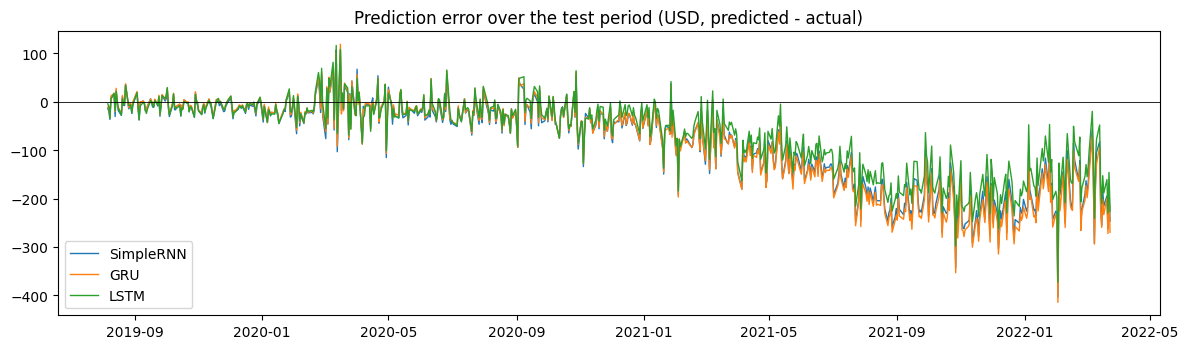

In [14]:
fig, ax = plt.subplots(figsize=(12, 3.6))
for kind, p in pred_test.items():
    ax.plot(dates_test, to_usd(p) - actual, linewidth=1, label=kind)
ax.axhline(0, color="black", linewidth=0.6)
ax.set_title("Prediction error over the test period (USD, predicted - actual)")
ax.legend()
save("test_errors.png")

**Discussion.**
- *Overfitting:* the models do not memorise the training set — the gap between training and validation error is no
  wider than the one persistence shows on the same days (section 7). But early stopping does **not** always end
  training before the limit: LSTM reached the 100-epoch cap in 3 of its 5 seeds, with the best epoch at 93, 99 and 99,
  so it was still improving when it ran out of epochs. `MAX_EPOCHS` is a binding constraint for LSTM, not a formality.
- *Underfitting:* on the training period every model stays **above** the persistence error (7.60–7.97 USD against
  6.39), so none of them has even learned to match "tomorrow = today" on the data it was trained on.
- *Limitation, extrapolation:* the target is the raw price level, scaled with Min-Max fitted on training data as
  requirement §4.5 asks. Every test price lies above the highest training price, so the models must predict values they
  never saw. The `tanh` hidden state is bounded to [-1, 1], which caps the output of `Dense(1)`, and the predictions
  fall further below the actual price as it rises. The ratios in section 7 make the mechanism visible: on validation,
  which only just leaves the training range, the models are 1.05 to 1.16 times the baseline error; on test, which
  leaves it completely, 2.90 to 5.77 times.
- *Limitation, seed variance:* over 5 seeds the test RMSE spans 120–280 USD for SimpleRNN, 122–187 for GRU and
  72–181 for LSTM, a factor of 2.3 to 2.5 within one architecture. A single-seed result would mostly measure the seed.
- *Limitation, validation does not predict test:* across the 15 runs the correlation between validation RMSE and test
  RMSE is only 0.34, and for GRU and LSTM the seed chosen on validation is not the best one on test (LSTM: 99.2 USD
  for the chosen seed against 72.4 for the best). Model selection is reliable only while the selection data and the
  evaluation data sit in the same range, which is exactly what this split breaks.
- *Limitation, the data itself:* daily stock prices are close to a random walk, so today's close already carries
  most of what can be known about tomorrow's. The section 9 study agrees: a 10-day window scores as well as the
  required 30-day one (17.29 against 18.02 USD) and is the most stable of the four. A high R² on price level is easy
  for any method that follows the price and is not evidence of a learned temporal pattern.
- *Limitation, capacity is not the bottleneck:* widening the layer from 16 to 128 units improves validation RMSE from
  28.88 to 17.50 USD, but the last doubling (64 → 128) is worth 0.5 USD, inside the seed noise, and 128 units still
  lose to the 16.19 USD of persistence. A larger or deeper network would not close a gap that comes from the target
  leaving the training range.
- *Limitation, experiments:* one chronological split; 5 seeds for the main models and 3 per setting in section 9;
  only `Close` as input.

## 11. Save the trained models
The seed with the lowest validation loss for each architecture.

In [15]:
for kind, b in best.items():
    b["keras"].save(os.path.join(MODELS_DIR, f"{kind.lower()}.keras"))
print(sorted(os.listdir(MODELS_DIR)))

['gru.keras', 'lstm.keras', 'simplernn.keras']
